# `survivorship.ipynb`

This notebook does the survivorship analysis used in Figure 5 and supplemental information.

In [305]:
import numpy as np
import pandas as pd

from scipy.stats import ecdf

from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import testis_model as tm

import os

In [306]:
small_label_settings = {
    'font.family': 'Arial',
    'font.size': 7,              # base font size
    'xtick.labelsize': 5,        # x-axis tick label size
    'ytick.labelsize': 5,        # y-axis tick label size
    'axes.labelsize': 7,         # axis label size
    'axes.titlesize': 7,         # title size
    'legend.fontsize': 7,        # legend font size
    'figure.titlesize': 7        # figure title size
}

In [307]:
filepath = os.path.join('..', 'model_simulations', 'all_clone_results.csv')
df = pd.read_csv(filepath)

experimental_scenario = 'full_pipeline_trunc'
df['died_early'] = df['last_time'] != df['max_time']
df.head()

,scenario,fish,clone,init_time,init_freq,last_time,min_time,max_time,max_freq,n_transient,size,avg_freq_change,r_opt,l_max,lower,upper,l_null,died_early
0,n1000_r10_y6,0,0,5.0,0.576271,26.0,5.0,26.0,0.962571,18,0.812932,-0.018395,7.778425,-212.832113,4.098904,16.090177,-1888.591559,False
1,n1000_r10_y6,0,1,5.0,0.232345,26.0,5.0,26.0,0.037429,18,0.094083,0.009282,6.179582,-205.600681,3.165454,13.058055,-849.881384,False
2,n1000_r10_y6,0,2,5.0,0.057203,12.0,5.0,26.0,0.000000,8,0.011535,0.007869,9.129557,-71.589854,4.015566,21.601640,-380.809396,True
3,n1000_r10_y6,0,3,5.0,0.067090,9.0,5.0,26.0,0.000000,5,0.013065,0.013771,14.911638,-54.953492,4.885854,53.652249,-518.201125,True
4,n1000_r10_y6,0,4,5.0,0.032486,16.0,5.0,26.0,0.000000,11,0.065992,0.002440,17.537116,-126.057567,8.900827,38.057712,-1569.843414,True


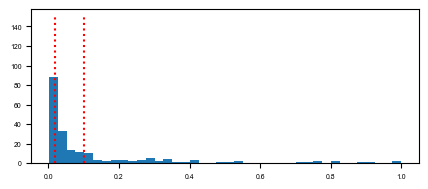

In [308]:
small_cutoff = 0.02
large_cutoff = 0.10

fig, ax = plt.subplots(figsize = (5, 2))

real_df = df.query('scenario == @experimental_scenario')
ax.hist(real_df['init_freq'], bins=40)
ax.vlines(x=small_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)
ax.vlines(x=large_cutoff, ymin=0, ymax=150, colors='r', linestyles='dotted', zorder=1)

In [309]:
print(f"""\
{100*(real_df['init_freq'] < small_cutoff).mean():.1f}% of clones have a size below {small_cutoff:.2f}, \
{100*((real_df['init_freq'] > small_cutoff) & (real_df['init_freq'] < large_cutoff)).mean():.1f}% \
have a size between {small_cutoff:.2f} and {large_cutoff:.2f}, and \
{100*(real_df['init_freq'] > large_cutoff).mean():.1f}% of clones have a size above {large_cutoff:.2f}.\
""")

36.3% of clones have a size below 0.02, 34.8% have a size between 0.02 and 0.10, and 28.9% of clones have a size above 0.10.


In [310]:
df.loc[df['init_freq'] < large_cutoff, 'tertile'] = 'medium'
df.loc[df['init_freq'] < small_cutoff, 'tertile'] = 'small'
df.loc[df['init_freq'] >= large_cutoff, 'tertile'] = 'large'

In [312]:
df[df['last_time'].isna()]['scenario'].unique()

array(['n1000_r3_y6_realistic', 'n1000_r5_y6_realistic',
       'n1000_r2_y6_realistic', 'n1000_r8_y6_realistic',
       'full_pipeline_trunc', 'n500_r36_y3', 'n1000_r9_y6_realistic',
       'n1000_r15_y6_realistic', 'n1000_r1.5_y6_realistic', 'n500_r15_y3',
       'n1000_r10_y6_realistic', 'n1000_r36_y9', 'n1000_r7_y6_realistic',
       'n1000_r2.5_y6_realistic', 'n1000_r36_y6', 'n500_r36_y9',
       'n1000_r6_y6_realistic', 'n500_r36_y6'], dtype=object)

In [204]:
# TEMPORARY, REMOVE AFTER RERUNNING SIMS
df = df[~df['last_time'].isna()].copy()

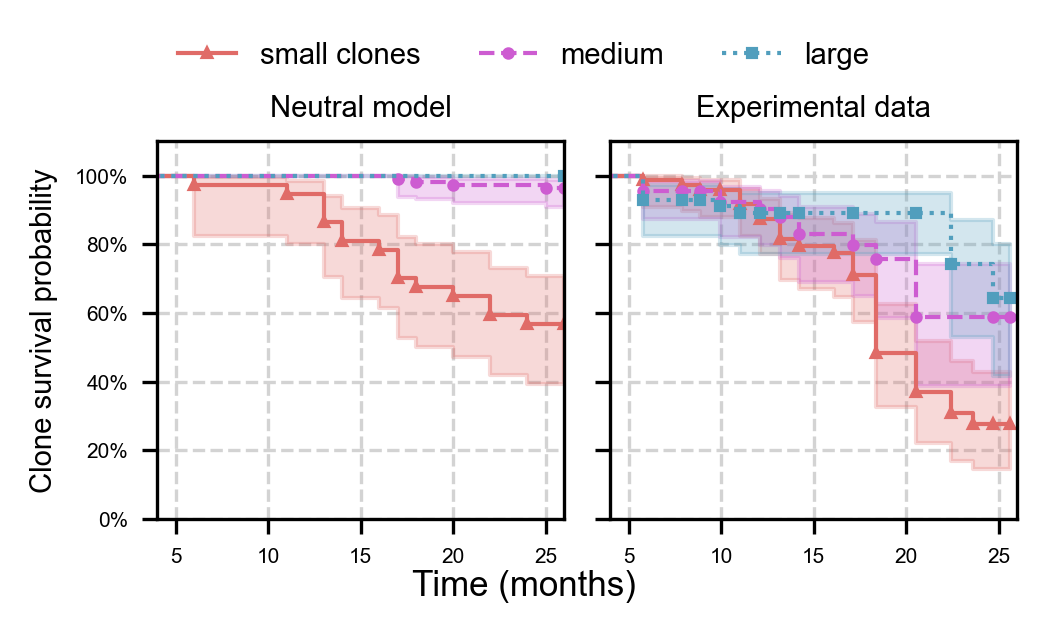

In [163]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, ax = plt.subplots(1, 2, figsize=(3.5, 2), dpi = 300, sharey=True)

n_experimental_fish = 24
compare_scenario = 'n1000_r0.5_y6'

kmf = dict()
subset = dict()
for i, s in enumerate([compare_scenario, experimental_scenario]):
    # Filter the DataFrame
    
    # Instantiate the KaplanMeierFitter
    kmf[s, 'sm'] = KaplanMeierFitter()
    kmf[s, 'md'] = KaplanMeierFitter()
    kmf[s, 'lg'] = KaplanMeierFitter()

    data = df.query('scenario == @s')
    if s == experimental_scenario:
        subset[s, 'sm'] = data.query('tertile == "small"')
        subset[s, 'md'] = data.query('tertile == "medium"')
        subset[s, 'lg'] = data.query('tertile == "large"')
    else:
        # subset 'fish <= 30' so that we are comparing similar amounts of
        # experimental & real data.
        subset[s, 'sm'] = data.query('tertile == "small" and fish <= @n_experimental_fish')
        subset[s, 'md'] = data.query('tertile == "medium" and fish <= @n_experimental_fish')
        subset[s, 'lg'] = data.query('tertile == "large" and fish <= @n_experimental_fish')

    sm, md, lg = subset[s, 'sm'], subset[s, 'md'], subset[s, 'lg']
    
    # Fit the model — assuming all events are observed (no censoring)
    kmf[s, 'sm'].fit(durations = sm['last_time'], event_observed = sm['died_early'])
    kmf[s, 'md'].fit(durations = md['last_time'], event_observed = md['died_early'])
    kmf[s, 'lg'].fit(durations = lg['last_time'], event_observed = lg['died_early'])
    
    # Plot the survival curve
    kmf[s, 'sm'].plot_survival_function(ax = ax[i], label='small clones', color = '#e06b67', linewidth=1, marker = '^', markersize = 2)
    kmf[s, 'md'].plot_survival_function(ax = ax[i], label='medium', color = '#cd5cd1', linewidth=1, linestyle = '--', marker = 'o', markersize = 2)
    kmf[s, 'lg'].plot_survival_function(ax = ax[i], label='large', color = '#519ebd', linewidth=1, linestyle = ':', marker = 's', markersize = 2)
    
    ax[i].set_xlabel('')
    
    ax[i].grid(True, linestyle='--', linewidth=0.8, color='lightgray')
    ax[i].set_axisbelow(True) 
    ax[i].set_xticks([5, 10, 15, 20, 25])
    ax[i].set_xlim([4, 26])
    ax[i].set_ylim([0, 1.1])
    ax[i].set_title('Neutral model' if i == 0 else 'Experimental data')
    ax[i].legend_.remove()

ax[0].set_ylabel('Clone survival probability')
ax[0].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))

# After plotting all curves
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=False)
fig.supxlabel("Time (months)", y=0.1)

plt.tight_layout()
plt.savefig('./images/survivorship-tertile.svg', transparent = True, bbox_inches = 'tight')

In [296]:
exp_scenario = 'full_pipeline'
sim_scenario = 'n1000_r2_y6'

df[df['scenario'].isin([exp_scenario, sim_scenario])].groupby('scenario').agg({'died_early': 'mean'})
# Slightly more of the simulations died early in this comparison.

,died_early
scenario,
full_pipeline,0.350000
n1000_r2_y6,0.251908


In [136]:
df_sub['died_early'].mean()

np.float64(0.3464285714285714)

In [148]:
from lifelines import CoxPHFitter

# Subset to relevant scenarios
df_sub = df[df['scenario'].isin([exp_scenario, sim_scenario])].copy()

# Set scenario as categorial and re-order.
df_sub['scenario'] = pd.Categorical(df_sub['scenario'])
df_sub['scenario'] = df_sub['scenario'].cat.reorder_categories(
    [sim_scenario, exp_scenario]
)

# Ensure 'scenario' is treated as a categorical variable
df_sub['scenario'] = df_sub['scenario'].astype('category')

# Fit Cox model with interaction
cph = CoxPHFitter()
cph.fit(df_sub, duration_col='last_time', event_col='died_early', formula='init_freq * scenario')

# Print results
print("Interaction model: init_freq × scenario")
cph.print_summary()

Interaction model: init_freq × scenario


<lifelines.CoxPHFitter: fitted with 1169 total observations, 779 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
      baseline estimation = breslow
   number of observations = 1169
number of events observed = 390
   partial log-likelihood = -2399.39
         time fit was run = 2025-12-13 23:39:48 UTC

---
                                      coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                             
init_freq                           -29.92      0.00      1.98          -33.80          -26.04                0.00                0.00
scenario[T.full_pipeline]            -1.40      0.25      0.15           -1.70           -1.11                0.18                0.33
init_freq:scenario[T.full_pipeline]  28.31  1.96e+12      2.16           24.08           32.53            2.86e+10            1.35e+14

                                     cmp to      z      p  -log2(p)
covariate                                                          
init_freq                              0.00 -15.12 <0.005    169.25
scenario[T.full_pipeline]              0.00  -9.24 <0.005     65.19
init_freq:scenario[T.full_pipeline]    0.00  13.12 <0.005    128.14
---
Concordance = 0.82
Partial AIC = 4804.79
log-likelihood ratio test = 499.46 on 3 df
-log2(p) of ll-ratio test = 356.13

In [138]:
results = proportional_hazard_test(cph, df_sub, time_transform='rank')
print(results.summary)

                                     test_statistic             p   -log2(p)
init_freq                                 73.020170  1.283316e-17  56.112901
init_freq:scenario[T.full_pipeline]       74.415484  6.329063e-18  57.132714
scenario[T.full_pipeline]                 74.642324  5.642058e-18  57.298484


In [143]:
from lifelines import CoxPHFitter

# Subset to relevant scenarios
df_sub = df[df['scenario'].isin([exp_scenario])].copy()
df_sub['logit_init_freq'] = np.log(df_sub['init_freq'] / (1 - df_sub['init_freq']))

# Fit Cox model with interaction
cph = CoxPHFitter()
cph.fit(df_sub, duration_col='last_time', event_col='died_early', formula='init_freq')

# Print results
print("Interaction model: init_freq")
cph.print_summary()

Interaction model: init_freq


<lifelines.CoxPHFitter: fitted with 280 total observations, 182 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
      baseline estimation = breslow
   number of observations = 280
number of events observed = 98
   partial log-likelihood = -476.07
         time fit was run = 2025-12-13 23:34:11 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
init_freq -1.95      0.14      0.90           -3.73           -0.18                0.02                0.83

           cmp to     z    p  -log2(p)
covariate                             
init_freq    0.00 -2.16 0.03      5.02
---
Concordance = 0.58
Partial AIC = 954.14
log-likelihood ratio test = 6.23 on 1 df
-log2(p) of ll-ratio test = 6.32

In [144]:
results = proportional_hazard_test(cph, df_sub, time_transform='rank')
print(results.summary)

           test_statistic         p  -log2(p)
init_freq        2.653652  0.103312  3.274916


So experimental data fits assumptions of Cox and shows significant dependence on initial frequency.

In [300]:
from lifelines import WeibullAFTFitter

sim_scenario = 'n1000_r2_y6_realistic'

# Subset to relevant scenarios
df_sub = df[df['scenario'].isin([exp_scenario, sim_scenario])].copy()

# Set scenario as categorial and re-order.
df_sub['scenario'] = pd.Categorical(df_sub['scenario'])
df_sub['scenario'] = df_sub['scenario'].cat.reorder_categories(
    [sim_scenario, exp_scenario]
)

# Ensure 'scenario' is treated as a categorical variable
df_sub['scenario'] = df_sub['scenario'].astype('category')

aft = WeibullAFTFitter()
aft.fit(df_sub, duration_col="last_time", event_col="died_early", formula="init_freq * scenario")
aft.print_summary()

<lifelines.WeibullAFTFitter: fitted with 453 total observations, 317 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
   number of observations = 453
number of events observed = 136
           log-likelihood = -585.80
         time fit was run = 2025-12-14 22:31:35 UTC

---
                                              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param   covariate                                                                                                                             
lambda_ Intercept                             2.62     13.75      0.11            2.41            2.83               11.16               16.95
        init_freq                            18.87  1.57e+08      3.65           11.72           26.02            1.24e+05            2.00e+11
        scenario[T.full_pipeline]             0.62      1.86      0.12            0.39            0.86                1.47                2.36
        init_freq:scenario[T.full_pipeline] -18.09      0.00      3.66          -25.27          -10.92                0.00                0.00
rho_    Intercept                             0.87      2.40      0.07            0.74            1.01                2.10                2.74

                                             cmp to     z      p  -log2(p)
param   covariate                                                         
lambda_ Intercept                              0.00 24.57 <0.005    440.55
        init_freq                              0.00  5.17 <0.005     22.06
        scenario[T.full_pipeline]              0.00  5.19 <0.005     22.19
        init_freq:scenario[T.full_pipeline]    0.00 -4.94 <0.005     20.32
rho_    Intercept                              0.00 12.86 <0.005    123.24
---
Concordance = 0.72
AIC = 1181.60
log-likelihood ratio test = 92.59 on 3 df
-log2(p) of ll-ratio test = 63.83

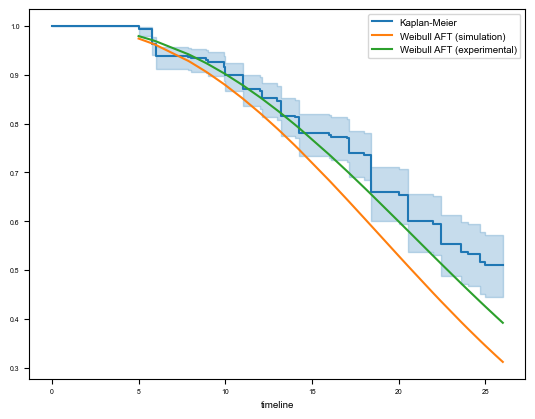

In [171]:
from lifelines import KaplanMeierFitter, WeibullAFTFitter
import matplotlib.pyplot as plt
import pandas as pd

# Fit KM
kmf = KaplanMeierFitter()
kmf.fit(df_sub["last_time"], event_observed=df_sub["died_early"])
kmf.plot_survival_function(label="Kaplan-Meier")

# Fit Weibull AFT (already fitted as aft)
# Example covariates: median init_freq, scenario = simulation
example_cov_sim = pd.DataFrame({
    "init_freq": [df_sub["init_freq"].median()],
    "scenario": [sim_scenario]
})
example_cov_exp = pd.DataFrame({
    "init_freq": [df_sub["init_freq"].median()],
    "scenario": [exp_scenario]
})

aft_surv_sim = aft.predict_survival_function(example_cov_sim)
aft_surv_exp = aft.predict_survival_function(example_cov_exp)

plt.plot(aft_surv_sim.index, aft_surv_sim.values, label="Weibull AFT (simulation)")
plt.plot(aft_surv_exp.index, aft_surv_exp.values, label="Weibull AFT (experimental)")
plt.legend()
plt.show()

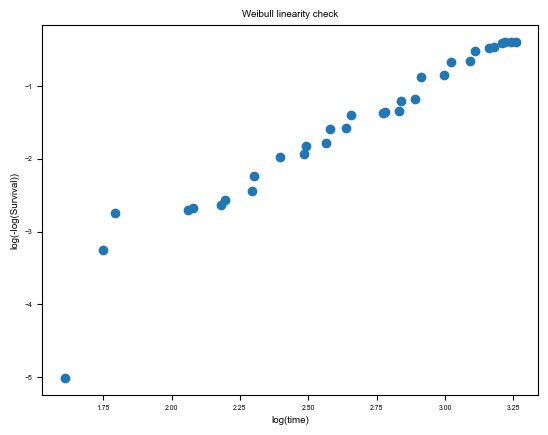

In [172]:
import numpy as np

kmf.fit(df_sub["last_time"], event_observed=df_sub["died_early"])
surv = kmf.survival_function_

plt.plot(np.log(surv.index), np.log(-np.log(surv.values)), marker="o", linestyle="none")
plt.xlabel("log(time)")
plt.ylabel("log(-log(Survival))")
plt.title("Weibull linearity check")
plt.show()

In [289]:
import pandas as pd
from lifelines import WeibullAFTFitter

rs = [0.5, 1, 1.5, 2, 2.5, 3, 4, 5]
rows = []

for r in rs:
    sim_scenario = f'n1000_r{r}_y6_realistic'
    
    # Subset to relevant scenarios
    df_sub = df[df['scenario'].isin([exp_scenario, sim_scenario])].copy()
    
    # Set scenario as categorical and re-order
    df_sub['scenario'] = pd.Categorical(df_sub['scenario'])
    df_sub['scenario'] = df_sub['scenario'].cat.reorder_categories(
        [sim_scenario, exp_scenario]
    )
    df_sub['scenario'] = df_sub['scenario'].astype('category')
    
    aft = WeibullAFTFitter()
    aft.fit(df_sub, duration_col="last_time", event_col="died_early", formula="init_freq * scenario")
    summary = aft.summary
    
    # Collect results for this r
    row = {"r": r}
    for term in ['Intercept', 'init_freq', f'scenario[T.{exp_scenario}]', f'init_freq:scenario[T.{exp_scenario}]']:
        coef = summary.loc[('lambda_', term), "coef"]
        pval = summary.loc[('lambda_', term), "p"]
        row[term] = f"{coef:.3f} (p={pval:.3g})"

    overall_survive = df_sub.query('scenario == @sim_scenario')['died_early'].mean() * 100
    row['overall_survive'] = f'{overall_survive:.0f}%'
    rows.append(row)

# Build DataFrame
results_df = pd.DataFrame(rows)
results_df.set_index("r", inplace=True)

In [290]:
rename_dict = {
    "Intercept": "Lambda Intercept",
    "init_freq": "Initial Frequency",
    "scenario[T.full_pipeline]": "Scenario (full_pipeline)",
    "init_freq:scenario[T.full_pipeline]": "Interaction (Init Freq × Scenario)",
    'overall_survive': 'Overall survival'
}

results_df = results_df.rename(columns=rename_dict)

In [291]:
# results_df_reset = results_df.reset_index(drop=True)
results_df

,Lambda Intercept,Initial Frequency,Scenario (full_pipeline),Interaction (Init Freq × Scenario),Overall survival
r,,,,,
0.5,3.250 (p=1.87e-103),33.092 (p=0.00263),-0.019 (p=0.906),-32.335 (p=0.00329),7%
1.0,2.606 (p=7.27e-88),49.338 (p=5.71e-07),0.649 (p=6.78e-06),-48.540 (p=8.63e-07),15%
1.5,2.832 (p=1.06e-111),19.289 (p=4.51e-05),0.424 (p=0.00211),-18.488 (p=9.49e-05),18%
2.0,2.621 (p=2.41e-133),18.874 (p=2.29e-07),0.623 (p=2.09e-07),-18.094 (p=7.61e-07),22%
2.5,3.018 (p=7.26e-262),5.705 (p=4.01e-05),0.225 (p=0.0245),-4.928 (p=0.000577),24%
3.0,2.656 (p=5.6e-124),13.844 (p=4.67e-07),0.619 (p=1.42e-06),-13.013 (p=2.58e-06),23%
4.0,2.168 (p=8.74e-57),24.403 (p=1.13e-09),1.064 (p=2.83e-13),-23.643 (p=4.08e-09),23%
5.0,2.874 (p=5.11e-242),4.352 (p=1.44e-05),0.386 (p=0.00016),-3.544 (p=0.00094),31%


In [270]:
results_df_reset.to_clipboard(index=False)



   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.



<lifelines.StatisticalResult: proportional_hazard_test>
 null_distribution = chi squared
degrees_of_freedom = 1
             model = <lifelines.CoxPHFitter: fitted with 895 total observations, 580 right-censored observations>
         test_name = proportional_hazard_test

---
                test_statistic      p  -log2(p)
init_freq km            113.61 <0.005     85.70
          rank          111.68 <0.005     84.30



1. Variable 'init_freq' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'init_freq' might be incorrect. That is, there may
be non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'init_freq' using pd.cut, and then specify it in
`strata=['init_freq', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.h

[[<Axes: xlabel='rank-transformed time\n(p=0.0000)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0000)'>]]

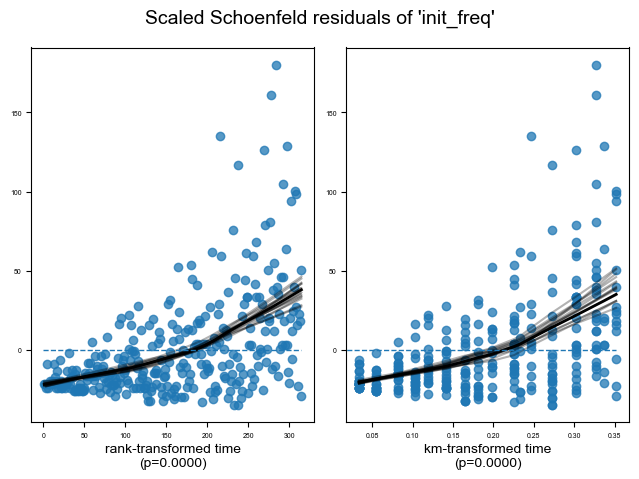

In [86]:
import matplotlib.pyplot as plt

# After fitting your Cox model as cph
cph.check_assumptions(df_sub, p_value_threshold=0.05, show_plots=True)

In [106]:
df_sub['init_bin'] = pd.cut(df_sub['init_freq'], bins=[0,0.2,0.5,1.0])

df_subsub = df_sub[['last_time', 'died_early', 'init_bin', 'init_freq']]
cph.fit(df_subsub, duration_col='last_time', event_col='died_early',
        strata=['init_bin'])

cph.print_summary()

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/lifelines/fitters/__init__.py:1280: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for stratum, df_ in df.groupby(strata):
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/lifelines/fitters/coxph_fitter.py:1868: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for stratum, stratified_X in X.groupby(self.strata):
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/lifelines/fitters/coxph_fitter.py:1868: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to ret

<lifelines.CoxPHFitter: fitted with 895 total observations, 580 right-censored observations>
             duration col = 'last_time'
                event col = 'died_early'
                   strata = init_bin
      baseline estimation = breslow
   number of observations = 895
number of events observed = 315
   partial log-likelihood = -1834.78
         time fit was run = 2025-12-12 15:56:52 UTC

---
            coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                   
init_freq -25.61      0.00      1.77          -29.08          -22.14                0.00                0.00

           cmp to      z      p  -log2(p)
covariate                                
init_freq    0.00 -14.47 <0.005    155.25
---
Concordance = 0.81
Partial AIC = 3671.56
log-likelihood ratio test = 314.69 on 1 df
-log2(p) of ll-ratio test = 231.48

In [107]:
results = proportional_hazard_test(cph, df_subsub, time_transform='rank')
print(results.summary)

           test_statistic             p   -log2(p)
init_freq       98.095735  3.986365e-23  74.409272


/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/lifelines/fitters/coxph_fitter.py:1868: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for stratum, stratified_X in X.groupby(self.strata):
